# 01 — Replikasi: *A Hybrid CNN and RNN Variant Model for Music Classification*

**Mata kuliah:** Pengolahan Sinyal Digital — Project Minggu 1 (Replikasi)
**Kelompok 1:** Kenza Athallah Nandana Wijaya · Mohammad Adib Alfiyan (L0223028) · Veenda Putri Divo

**Paper acuan:** Ashraf, M., Abid, F., Din, I. U., Rasheed, J., Yesiltepe, M., Yeo, S. F., & Ersoy, M. T. (2023).
*A Hybrid CNN and RNN Variant Model for Music Classification.* Applied Sciences, 13(3), 1476.
https://doi.org/10.3390/app13031476

**Dataset:** GTZAN (Tzanetakis & Cook, 2002) — versi Kaggle `andradaolteanu/gtzan-dataset-music-genre-classification`.

**Target replikasi (Tabel 2 paper, akurasi %):**

| Model | Mel-spectrogram | MFCC |
|---|---|---|
| CNN+LSTM | 87.20 | 76.40 |
| CNN+Bi-LSTM | 88.00 | 73.69 |
| CNN+GRU | 87.78 | 71.50 |
| CNN+Bi-GRU | **89.30** | 76.30 |

**Lingkungan:** Kaggle Notebook, GPU T4, TensorFlow/Keras. Aktifkan *Settings → Accelerator → GPU T4* dan tambahkan dataset lewat *Add Input*.

**Alur notebook**
1. Setup & reproducibility
2. Inventaris dataset
3. Segmentasi 3 detik + dua protokol split (A per-segmen, B per-lagu)
4. Ekstraksi fitur (STFT → mel → log → [DCT → MFCC])
5. Normalisasi + 4 arsitektur hybrid
6. Fungsi training/evaluasi/log
7. Eksperimen replikasi (+ diagnosis stabilitas)
8. Rekap hasil vs paper + gambar
9. Paket hasil (zip)

> Notebook ini bisa dijalankan ulang (*resume*): eksperimen yang sudah tercatat di `log_eksperimen.csv` otomatis dilewati.
> Total waktu ±7 jam di GPU T4 → disarankan dijalankan via **Save Version → Save & Run All (Commit)**.

## 0. Konfigurasi

In [1]:
# ============================================================
# KONFIGURASI UTAMA
# ============================================================
DATA_ROOT      = "/kaggle/input"     # lokasi dataset (dicari otomatis di bawah folder ini)
WORK_DIR       = "/kaggle/working"   # semua output disimpan di sini
SEED           = 42
RUN_SMOKE_TEST = False   # True -> uji 3 epoch dulu untuk cek waktu & konvergensi
RUN_DIAGNOSIS  = True    # True -> ulangi CNN+LSTM mel_1024 (seed 43, 44) & uji gradient clipping
VERBOSE        = 0       # 0 = senyap, 2 = tampilkan log per epoch

## 1. Setup environment & reproducibility

In [2]:
import os, random, glob, json, time, platform, subprocess
from datetime import datetime
import numpy as np
import pandas as pd
import librosa, librosa.display
import soundfile as sf
import tensorflow as tf
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

os.makedirs(WORK_DIR, exist_ok=True)

def set_seed(seed=SEED):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
set_seed()

versions = {
    "python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
    "librosa": librosa.__version__, "soundfile": sf.__version__, "tensorflow": tf.__version__,
    "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__,
}
for k, v in versions.items():
    print(f"{k:13s}: {v}")
print("\nGPU:", tf.config.list_physical_devices("GPU"))

# ---------- Log deviasi (tanpa duplikat bila sel dijalankan ulang) ----------
DEVIASI = {}
def catat_deviasi(aspek, paper, kita, alasan):
    DEVIASI[aspek] = {"aspek": aspek, "paper": paper, "kita": kita, "alasan": alasan}
    with open(os.path.join(WORK_DIR, "log_deviasi.json"), "w") as f:
        json.dump(list(DEVIASI.values()), f, indent=2, ensure_ascii=False)

python       : 3.13.15
numpy        : 2.1.3
pandas       : 2.3.3
librosa      : 0.11.0
soundfile    : 0.14.0
tensorflow   : 2.20.0
scikit-learn : 1.6.1
matplotlib   : 3.10.0

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2. Inventaris dataset GTZAN

In [3]:
cands = glob.glob(os.path.join(DATA_ROOT, "**", "genres_original"), recursive=True)
assert cands, "Folder genres_original tidak ditemukan. Cek Add Input."
DATA_DIR = cands[0]
print("/kaggle/input/datasets/andradaolteanu/gtzan-dataset-music-genre-classification", DATA_DIR)

GENRES = sorted(d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d)))
print("Genre:", GENRES, f"({len(GENRES)} genre)\n")

rows = []
for g in GENRES:
    for f in sorted(glob.glob(os.path.join(DATA_DIR, g, "*.wav"))):
        try:
            info = sf.info(f)
            rows.append({"file": f, "genre": g, "sr": info.samplerate, "channels": info.channels,
                         "duration": round(info.duration, 3), "ok": True})
        except Exception as e:
            rows.append({"file": f, "genre": g, "sr": None, "channels": None,
                         "duration": None, "ok": False})
            print("RUSAK:", os.path.basename(f), "->", type(e).__name__)

meta = pd.DataFrame(rows)
print(f"\nTotal file : {len(meta)}")
print(f"File valid : {meta.ok.sum()}")
print("\nJumlah per genre:\n", meta.groupby("genre").ok.sum().to_string())
print("\nSample rate unik :", meta.sr.dropna().unique())
print("Channel unik     :", meta.channels.dropna().unique())
print("Durasi (detik)   :\n", meta.duration.describe().round(3).to_string())

/kaggle/input/datasets/andradaolteanu/gtzan-dataset-music-genre-classification /kaggle/input/datasets/andradaolteanu/gtzan-dataset-music-genre-classification/Data/genres_original
Genre: ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock'] (10 genre)

RUSAK: jazz.00054.wav -> LibsndfileError

Total file : 1000
File valid : 999

Jumlah per genre:
 genre
blues        100
classical    100
country      100
disco        100
hiphop       100
jazz          99
metal        100
pop          100
reggae       100
rock         100

Sample rate unik : [22050.]
Channel unik     : [1.]
Durasi (detik)   :
 count    999.000
mean      30.024
std        0.081
min       29.932
25%       30.000
50%       30.013
75%       30.013
max       30.649


## 3. Segmentasi 30 s → 10 × 3 s, dan dua protokol split

Paper menyebut split **8:1:1** tanpa menjelaskan levelnya. Kita uji dua kemungkinan:
- **Protokol A (per-segmen):** dugaan protokol paper — potongan dari lagu yang sama bisa ada di train *dan* test (*leakage*).
- **Protokol B (per-lagu):** seluruh 10 potongan satu lagu berada di set yang sama — bebas leakage.

In [4]:
SR       = 22050
CLIP_SEC = 30
SEG_SEC  = 3
N_SEG    = CLIP_SEC // SEG_SEC          # 10 segmen per lagu
SEG_LEN  = SR * SEG_SEC                 # 66.150 sampel
CLIP_LEN = SR * CLIP_SEC                # 661.500 sampel

meta_ok = meta[meta.ok].reset_index(drop=True).copy()
meta_ok["track_id"] = meta_ok.index
label2id = {g: i for i, g in enumerate(GENRES)}
meta_ok["label"] = meta_ok.genre.map(label2id)

X_audio  = np.zeros((len(meta_ok) * N_SEG, SEG_LEN), dtype=np.float32)
seg_rows, n_pad = [], 0
for i, r in meta_ok.iterrows():
    y, sr = sf.read(r.file, dtype="float32")      # sudah 22.050 Hz mono -> tanpa resampling
    assert sr == SR and y.ndim == 1
    if len(y) < CLIP_LEN:                         # klip < 30 s -> zero-pad di ekor
        n_pad += 1
        y = np.pad(y, (0, CLIP_LEN - len(y)))
    y = y[:CLIP_LEN]                              # klip > 30 s -> dipotong
    for s in range(N_SEG):
        k = i * N_SEG + s
        X_audio[k] = y[s * SEG_LEN:(s + 1) * SEG_LEN]
        seg_rows.append((k, r.track_id, s, r.label, r.genre))

seg = pd.DataFrame(seg_rows, columns=["seg_idx", "track_id", "seg_no", "label", "genre"])
y_seg = seg.label.values
print(f"Segmen       : {X_audio.shape}  ({X_audio.nbytes/1e9:.2f} GB)")
print(f"Lagu di-pad  : {n_pad} (durasi < 30 s)")

# Protokol A: split per SEGMEN 8:1:1
idx = seg.seg_idx.values
A_tr, A_tmp = train_test_split(idx, test_size=0.2, stratify=y_seg, random_state=SEED)
A_va, A_te  = train_test_split(A_tmp, test_size=0.5, stratify=y_seg[A_tmp], random_state=SEED)

# Protokol B: split per LAGU 8:1:1
tid, tlab = meta_ok.track_id.values, meta_ok.label.values
T_tr, T_tmp = train_test_split(tid, test_size=0.2, stratify=tlab, random_state=SEED)
T_va, T_te  = train_test_split(T_tmp, test_size=0.5, stratify=tlab[T_tmp], random_state=SEED)
to_seg = lambda tracks: seg.seg_idx[seg.track_id.isin(tracks)].values
B_tr, B_va, B_te = to_seg(T_tr), to_seg(T_va), to_seg(T_te)

SPLITS = {"A_segmen": {"train": A_tr, "val": A_va, "test": A_te},
          "B_lagu":   {"train": B_tr, "val": B_va, "test": B_te}}

for nama, sp in SPLITS.items():
    lagu = {k: set(seg.track_id.values[v]) for k, v in sp.items()}
    bocor = len(lagu["train"] & lagu["test"])
    print(f"{nama:9s} | train {len(sp['train']):5d} | val {len(sp['val']):4d} | test {len(sp['test']):4d}"
          f" | lagu test yang juga ada di train: {bocor}/{len(lagu['test'])}")

seg.to_csv(os.path.join(WORK_DIR, "segments.csv"), index=False)
with open(os.path.join(WORK_DIR, "splits.json"), "w") as f:
    json.dump({n: {k: v.tolist() for k, v in sp.items()} for n, sp in SPLITS.items()}, f)

catat_deviasi("Dataset", "GTZAN 1000 klip, format mp3",
              f"Versi Kaggle (andradaolteanu), .wav; {len(meta_ok)} klip valid (file rusak dibuang)",
              "Paper tidak menyebut sumber unduhan; jazz.00054 tidak bisa dibaca")
catat_deviasi("Segmentasi", "30 s -> 3 s, penanganan sisa tidak disebut",
              f"10 segmen non-overlap; {n_pad} klip < 30 s di-zero-pad, kelebihan dipotong",
              "Agar tiap lagu tepat 10 segmen")
catat_deviasi("Split", "8:1:1, level tidak disebut",
              "Protokol A per-segmen (dugaan paper) & B per-lagu, stratified, seed 42",
              "Ambiguitas paper; B untuk mengukur dampak leakage")

Segmen       : (9990, 66150)  (2.64 GB)
Lagu di-pad  : 9 (durasi < 30 s)
A_segmen  | train  7992 | val  999 | test  999 | lagu test yang juga ada di train: 648/648
B_lagu    | train  7990 | val 1000 | test 1000 | lagu test yang juga ada di train: 0/100


## 4. Ekstraksi fitur — mel-spectrogram (2 konfigurasi FFT) & MFCC

Alur PSD: **sinyal → Hann window → STFT → |X|² → mel filter bank (128) → log (dB) → [DCT → MFCC]**.

Paper tidak konsisten soal parameter STFT (Sec. 3.2: n_fft 1024; Sec. 4: 2048), jadi keduanya diuji.
Trade-off resolusi: Δf = fs/N dan panjang window = N/fs.

Konfigurasi | Δf = fs/N (Hz) | Panjang window (ms) | Hop (ms)
n_fft=1024  |          21.53 |                46.4 |     23.2
n_fft=2048  |          10.77 |                92.9 |     23.2
mel_1024  -> shape (9990, 128, 130)  |   42.3 s  |  min -54.9, max 33.9
mel_2048  -> shape (9990, 128, 130)  |   43.4 s  |  min -48.1, max 40.3
mfcc_20   -> shape (9990, 20, 130)  |   38.7 s  |  min -537.8, max 245.9


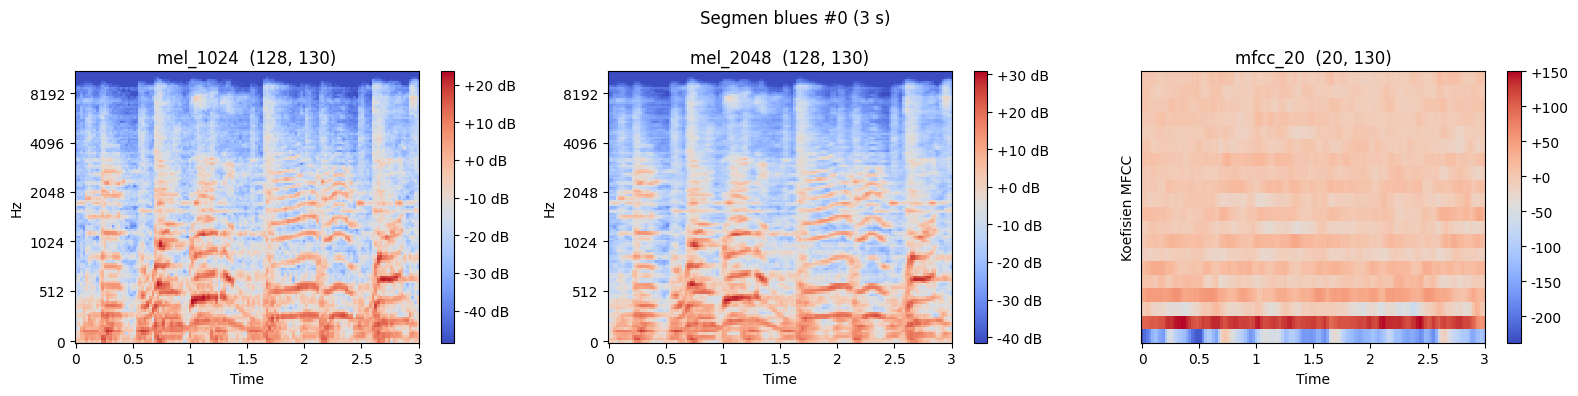

In [5]:
FEAT_DIR = os.path.join(WORK_DIR, "features")
os.makedirs(FEAT_DIR, exist_ok=True)

HOP = 512
FEAT_CFG = {
    "mel_1024": dict(kind="mel",  n_fft=1024, hop_length=HOP, n_mels=128),             # Sec. 3.2
    "mel_2048": dict(kind="mel",  n_fft=2048, hop_length=HOP, n_mels=128),             # Sec. 4
    "mfcc_20":  dict(kind="mfcc", n_fft=2048, hop_length=HOP, n_mels=128, n_mfcc=20),  # "13 to 20"
}

print("Konfigurasi | Δf = fs/N (Hz) | Panjang window (ms) | Hop (ms)")
for n_fft in (1024, 2048):
    print(f"n_fft={n_fft:4d}  | {SR/n_fft:14.2f} | {1000*n_fft/SR:19.1f} | {1000*HOP/SR:8.1f}")

def extract(X, cfg, batch=500):
    out = []
    for i in range(0, len(X), batch):
        S = librosa.feature.melspectrogram(y=X[i:i + batch], sr=SR, n_fft=cfg["n_fft"],
                                           hop_length=cfg["hop_length"], n_mels=cfg["n_mels"],
                                           window="hann", center=True, power=2.0)
        S_db = librosa.power_to_db(S, ref=1.0)                              # log-kompresi
        if cfg["kind"] == "mfcc":
            S_db = librosa.feature.mfcc(S=S_db, n_mfcc=cfg["n_mfcc"])        # DCT dari log-mel
        out.append(S_db.astype(np.float32))
    return np.concatenate(out)

FEATS = {}
for name, cfg in FEAT_CFG.items():
    t0 = time.time()
    FEATS[name] = extract(X_audio, cfg)
    np.save(os.path.join(FEAT_DIR, f"{name}.npy"), FEATS[name])
    print(f"{name:9s} -> shape {FEATS[name].shape}  |  {time.time()-t0:5.1f} s  |  "
          f"min {FEATS[name].min():.1f}, max {FEATS[name].max():.1f}")
np.save(os.path.join(FEAT_DIR, "labels.npy"), y_seg)

# Visualisasi satu segmen blues (padanan Fig. 5 & 7 paper)
k = seg.index[(seg.genre == "blues") & (seg.seg_no == 0)][0]
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, name in zip(ax, FEAT_CFG):
    is_mel = FEAT_CFG[name]["kind"] == "mel"
    img = librosa.display.specshow(FEATS[name][k], sr=SR, hop_length=HOP, x_axis="time",
                                   y_axis="mel" if is_mel else None, ax=a)
    a.set_title(f"{name}  {FEATS[name][k].shape}")
    fig.colorbar(img, ax=a, format="%+.0f" + (" dB" if is_mel else ""))
ax[2].set_ylabel("Koefisien MFCC")
plt.suptitle("Segmen blues #0 (3 s)"); plt.tight_layout()
plt.savefig(os.path.join(WORK_DIR, "fig_fitur_blues.png"), dpi=150); plt.show()

catat_deviasi("Parameter STFT",
              "Sec 3.2: n_fft 1024/hop 512, shape (128,129); Sec 4: window 2048/hop 512, shape (640,128)",
              "Dua konfigurasi diuji: mel_1024 & mel_2048, Hann, center=True -> (128,130)",
              "Paper tidak konsisten; shape (640,128) tidak bisa diturunkan dari segmen 3 s")
catat_deviasi("MFCC", "13–20 koefisien, parameter framing tidak disebut",
              "20 koefisien dari log-mel 128 band, n_fft 2048, hop 512",
              "Nilai pasti tidak disebut; 20 = default librosa")
catat_deviasi("Skala amplitudo", "Log/dB, referensi tidak disebut",
              "power_to_db(ref=1.0)", "Referensi tidak disebut")

## 5. Normalisasi + 4 arsitektur hybrid (Tabel 1 paper)

Dari paper: 5 blok Conv (128 filter, kernel 5, dropout 0,25), 3 layer RNN (128-128-64), LR 0,001, 50 epoch.
**Asumsi** (tidak disebut paper): Adam, batch 64, dense 128, MaxPool 2×2, sparse categorical cross-entropy.

In [6]:
HP = dict(
    conv_blocks=5, conv_filters=128, kernel=5, dropout=0.25,   # paper
    rnn_units=(128, 128, 64), lr=1e-3, epochs=50,              # paper
    dense_units=128, batch_size=64, optimizer="adam",          # ASUMSI
    clipnorm=None,                                             # None = setup paper (tanpa clipping)
)

def get_data(feat_name, protocol):
    # z-score per bin frekuensi / koefisien; statistik HANYA dari train set
    F, sp = FEATS[feat_name], SPLITS[protocol]
    mu  = F[sp["train"]].mean(axis=(0, 2), keepdims=True)
    std = F[sp["train"]].std(axis=(0, 2), keepdims=True) + 1e-6
    out = {}
    for part in ("train", "val", "test"):
        X = (F[sp[part]] - mu) / std
        X = np.transpose(X, (0, 2, 1))[..., None]            # (N, waktu, frekuensi, 1)
        out[part] = (X.astype(np.float32), y_seg[sp[part]])
    return out

RNN_CELL = {"lstm": layers.LSTM, "gru": layers.GRU}
MODELS = {"CNN+LSTM": ("lstm", False), "CNN+Bi-LSTM": ("lstm", True),
          "CNN+GRU":  ("gru",  False), "CNN+Bi-GRU":  ("gru",  True)}

def build_model(rnn="lstm", bidirectional=False, input_shape=(130, 128, 1), n_classes=10, hp=None):
    hp = hp or HP
    inp = keras.Input(shape=input_shape)
    x = inp
    for _ in range(hp["conv_blocks"]):                       # CNN front-end
        x = layers.Conv2D(hp["conv_filters"], hp["kernel"], padding="same", activation="relu")(x)
        x = layers.MaxPooling2D((2, 2), padding="same")(x)
        x = layers.Dropout(hp["dropout"])(x)
    t, f, c = x.shape[1], x.shape[2], x.shape[3]
    x = layers.Reshape((t, f * c))(x)                        # sumbu waktu -> barisan RNN
    for u in hp["rnn_units"]:                                # RNN back-end
        cell = RNN_CELL[rnn](u, return_sequences=True)
        x = layers.Bidirectional(cell)(x) if bidirectional else cell(x)
    x = layers.Flatten()(x)
    x = layers.Dense(hp["dense_units"], activation="relu")(x)
    x = layers.Dropout(hp["dropout"])(x)
    out = layers.Dense(n_classes, activation="softmax")(x)
    model = keras.Model(inp, out, name=f"CNN_{'Bi' if bidirectional else ''}{rnn.upper()}")
    opt = keras.optimizers.Adam(hp["lr"], clipnorm=hp["clipnorm"]) if hp["clipnorm"] \
          else keras.optimizers.Adam(hp["lr"])
    model.compile(optimizer=opt, loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

print(f"{'Model':12s} | {'Input':17s} | {'Seq RNN':7s} | Parameter")
for feat, shp in [("mel", (130, 128, 1)), ("mfcc", (130, 20, 1))]:
    for mname, (rnn, bi) in MODELS.items():
        m = build_model(rnn, bi, input_shape=shp)
        seq = m.get_layer(index=1 + 3 * HP["conv_blocks"]).output.shape[1]
        print(f"{mname:12s} | {feat:4s} {str(shp):12s} | {seq:7d} | {m.count_params():,}")
        keras.backend.clear_session()
build_model("gru", True).summary()

catat_deviasi("Arsitektur Bi-RNN", "Teks: 1 Bi-layer 128 + 1 RNN 128; Tabel 1: 3 layer RNN",
              "Mengikuti Tabel 1: 3 layer (128-128-64), masing-masing dibungkus Bidirectional",
              "Teks & tabel bertentangan; pilih desain seragam untuk 4 varian")
catat_deviasi("Pooling & reshape", "Ukuran pooling, padding, cara CNN->RNN tidak disebut",
              "MaxPool 2x2 padding 'same' tiap blok; sumbu waktu jadi barisan RNN (5 langkah)",
              "Asumsi paling sederhana yang kompatibel dg input mel (128) & MFCC (20)")
catat_deviasi("Hiperparameter training", "Optimizer, batch size, loss, lebar dense tidak disebut",
              "Adam lr 1e-3, batch 64, sparse categorical cross-entropy, dense 128 ReLU",
              "Pilihan standar; lr 0.001 dari baris Tabel 1 yang salah label")
catat_deviasi("Normalisasi input", "Tidak disebut",
              "z-score per bin frekuensi/koefisien, statistik dari train set tiap protokol",
              "Skala MFCC sangat timpang (koef-0 dominan); cegah kebocoran statistik test")
catat_deviasi("Pemilihan model", "Tidak disebut",
              "Bobot epoch dengan val_accuracy terbaik (restore_best_weights)", "Praktik standar")

Model        | Input             | Seq RNN | Parameter


I0000 00:00:1793550509.455177      24 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793550509.460680      24 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


CNN+LSTM     | mel  (130, 128, 1) |       5 | 2,193,802
CNN+Bi-LSTM  | mel  (130, 128, 1) |       5 | 2,940,554
CNN+GRU      | mel  (130, 128, 1) |       5 | 2,067,466
CNN+Bi-GRU   | mel  (130, 128, 1) |       5 | 2,638,730
CNN+LSTM     | mfcc (130, 20, 1) |       5 | 1,997,194
CNN+Bi-LSTM  | mfcc (130, 20, 1) |       5 | 2,547,338
CNN+GRU      | mfcc (130, 20, 1) |       5 | 1,920,010
CNN+Bi-GRU   | mfcc (130, 20, 1) |       5 | 2,343,818


Model: "CNN_BiGRU"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 130, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 130, 128, 128)  │         3,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 65, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 65, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 65, 64, 128)    │       409,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 33, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 33, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 33, 32, 128)    │       409,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 17, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 17, 16, 128)    │       409,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 9, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 9, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 9, 8, 128)      │       409,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 5, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 5, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 5, 512)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 5, 256)         │       493,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 5, 256)         │       296,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ (None, 5, 128)         │       123,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 640)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        82,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,638,730 (10.07 MB)

 Trainable params: 2,638,730 (10.07 MB)

 Non-trainable params: 0 (0.00 B)

## 6. Fungsi training + evaluasi + log eksperimen

- Metrik **level segmen** (seperti paper): accuracy, precision/recall/F1 macro.
- Metrik **level lagu** (tambahan): rata-rata probabilitas 10 segmen.
- Setiap run menambah 1 baris ke `log_eksperimen.csv`; history & prediksi disimpan.

In [7]:
LOG_PATH = os.path.join(WORK_DIR, "log_eksperimen.csv")
HIST_DIR = os.path.join(WORK_DIR, "history"); os.makedirs(HIST_DIR, exist_ok=True)
PRED_DIR = os.path.join(WORK_DIR, "pred");    os.makedirs(PRED_DIR, exist_ok=True)

def run_key(tag, model_name, feat_name, protocol, seed):
    return f"{tag}_{model_name}_{feat_name}_{protocol}_s{seed}".replace("+", "")

def sudah_jalan(m, f, p, seed=SEED, tag="replikasi"):
    if not os.path.exists(LOG_PATH):
        return False
    L = pd.read_csv(LOG_PATH)
    return ((L.tag == tag) & (L.model == m) & (L.fitur == f) & (L.protokol == p) & (L.seed == seed)).any()

def run_experiment(model_name, feat_name, protocol, epochs=None, seed=SEED, verbose=VERBOSE,
                   tag="replikasi", hp=None):
    hp = hp or HP
    set_seed(seed)
    keras.backend.clear_session()
    epochs = epochs or hp["epochs"]
    d = get_data(feat_name, protocol)
    (Xtr, ytr), (Xva, yva), (Xte, yte) = d["train"], d["val"], d["test"]

    rnn, bi = MODELS[model_name]
    model = build_model(rnn, bi, input_shape=Xtr.shape[1:], hp=hp)
    best = keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=epochs,
                                         restore_best_weights=True, mode="max")
    t0 = time.time()
    h = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=epochs,
                  batch_size=hp["batch_size"], callbacks=[best], verbose=verbose)
    train_time = time.time() - t0

    prob = model.predict(Xte, batch_size=256, verbose=0)
    pred = prob.argmax(1)
    acc = accuracy_score(yte, pred)
    p, r, f1, _ = precision_recall_fscore_support(yte, pred, average="macro", zero_division=0)

    te_idx = SPLITS[protocol]["test"]
    df = pd.DataFrame(prob); df["track"] = seg.track_id.values[te_idx]; df["y"] = yte
    g = df.groupby("track")
    track_acc = accuracy_score(g.y.first(), g[list(range(prob.shape[1]))].mean().values.argmax(1))

    row = dict(waktu=datetime.now().strftime("%Y-%m-%d %H:%M"), tag=tag, model=model_name,
               fitur=feat_name, protokol=protocol, seed=seed, epochs=epochs,
               best_epoch=int(np.argmax(h.history["val_accuracy"])) + 1,
               val_acc=round(max(h.history["val_accuracy"]), 4), test_acc=round(acc, 4),
               precision_macro=round(p, 4), recall_macro=round(r, 4), f1_macro=round(f1, 4),
               track_acc=round(track_acc, 4), n_params=model.count_params(),
               train_min=round(train_time / 60, 2),
               hp=json.dumps({k: hp[k] for k in ("lr", "batch_size", "dense_units", "dropout", "clipnorm")}))
    pd.DataFrame([row]).to_csv(LOG_PATH, mode="a", header=not os.path.exists(LOG_PATH), index=False)

    key = run_key(tag, model_name, feat_name, protocol, seed)
    pd.DataFrame(h.history).to_csv(os.path.join(HIST_DIR, key + ".csv"), index=False)
    np.save(os.path.join(PRED_DIR, key + ".npy"), np.stack([yte, pred]))
    return row, h

def cetak(i, n, row):
    print(f"[{i:2d}/{n}] {row['tag']:10s} {row['model']:12s} {row['fitur']:9s} {row['protokol']:9s} "
          f"s{row['seed']} | best_ep {row['best_epoch']:2d} | test_acc {row['test_acc']:.4f} | "
          f"f1 {row['f1_macro']:.4f} | track_acc {row['track_acc']:.4f} | {row['train_min']:.1f} mnt")

if RUN_SMOKE_TEST:
    row, h = run_experiment("CNN+Bi-GRU", "mel_1024", "A_segmen", epochs=3, verbose=1, tag="uji")
    print(f"\nPerkiraan 50 epoch: {row['train_min']/3*50:.1f} menit | val_acc:",
          [round(v, 3) for v in h.history["val_accuracy"]])

## 7. Eksperimen replikasi

| Prioritas | Eksperimen | Tujuan |
|---|---|---|
| P1 | 4 model × mel_1024 × Protokol A | Replikasi baris mel Tabel 2 |
| P2 | 4 model × mfcc_20 × Protokol A | Replikasi baris MFCC Tabel 2 |
| P3 | 4 model × mel_1024 × Protokol B | Dampak leakage |
| P4 | 4 model × mel_2048 × Protokol A | Dampak panjang window STFT |
| D  | CNN+LSTM mel_1024 A: seed 43, 44 & clipnorm 1.0 | Diagnosis ketidakstabilan |

In [8]:
RUNS = (
    [dict(m=m, f="mel_1024", p="A_segmen") for m in MODELS] +   # P1
    [dict(m=m, f="mfcc_20",  p="A_segmen") for m in MODELS] +   # P2
    [dict(m=m, f="mel_1024", p="B_lagu")   for m in MODELS] +   # P3
    [dict(m=m, f="mel_2048", p="A_segmen") for m in MODELS]     # P4
)
if RUN_DIAGNOSIS:
    RUNS += [dict(m="CNN+LSTM", f="mel_1024", p="A_segmen", seed=s) for s in (43, 44)]
    RUNS += [dict(m="CNN+LSTM", f="mel_1024", p="A_segmen", tag="clipnorm",
                  hp={**HP, "clipnorm": 1.0})]

t_all = time.time()
for i, r in enumerate(RUNS, 1):
    seed, tag = r.get("seed", SEED), r.get("tag", "replikasi")
    if sudah_jalan(r["m"], r["f"], r["p"], seed=seed, tag=tag):
        print(f"[{i:2d}/{len(RUNS)}] SKIP  {tag} {r['m']} {r['f']} {r['p']} s{seed}")
        continue
    row, _ = run_experiment(r["m"], r["f"], r["p"], seed=seed, tag=tag, hp=r.get("hp"))
    cetak(i, len(RUNS), row)
print(f"\nSelesai. Total {(time.time()-t_all)/3600:.2f} jam")

if RUN_DIAGNOSIS:
    catat_deviasi("Stabilitas training", "Tidak dilaporkan (single run, tanpa seed)",
                  "CNN+LSTM mel_1024 Protokol A diulang 3 seed (42, 43, 44) + 1 run clipnorm 1.0",
                  "Run seed 42 divergen; hasil gagal tetap dilaporkan, clipnorm hanya untuk diagnosis")

E0000 00:00:1793550522.828982      24 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/CNN_LSTM_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


[ 1/19] replikasi  CNN+LSTM     mel_1024  A_segmen  s42 | best_ep  2 | test_acc 0.3383 | f1 0.2564 | track_acc 0.3426 | 24.3 mnt


E0000 00:00:1793551999.466636      24 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/CNN_BiLSTM_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


[ 2/19] replikasi  CNN+Bi-LSTM  mel_1024  A_segmen  s42 | best_ep 44 | test_acc 0.9429 | f1 0.9431 | track_acc 0.9583 | 24.3 mnt


E0000 00:00:1793553460.901257      24 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/CNN_GRU_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


[ 3/19] replikasi  CNN+GRU      mel_1024  A_segmen  s42 | best_ep 42 | test_acc 0.9570 | f1 0.9569 | track_acc 0.9707 | 24.0 mnt


... (28 outputs left out)

E0000 00:00:1793570830.883543      24 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/CNN_LSTM_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


[18/19] replikasi  CNN+LSTM     mel_1024  A_segmen  s44 | best_ep  5 | test_acc 0.2292 | f1 0.1390 | track_acc 0.2392 | 24.0 mnt


E0000 00:00:1793572276.637812      24 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/CNN_LSTM_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


[19/19] clipnorm   CNN+LSTM     mel_1024  A_segmen  s42 | best_ep 50 | test_acc 0.9399 | f1 0.9399 | track_acc 0.9552 | 24.9 mnt

Selesai. Total 6.46 jam



=== CNN+LSTM (lr 0.001, seed 42) ===


E0000 00:00:1793573776.613289      24 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/CNN_LSTM_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


  ep  1 | loss 1.996 | val_acc 0.435 | aktivasi nol  66.0% | fitur mati  30.3% | grad_norm     2.877
  ep  2 | loss 1.606 | val_acc 0.514 | aktivasi nol  69.0% | fitur mati  30.3% | grad_norm     2.975
  ep  3 | loss 1.363 | val_acc 0.555 | aktivasi nol  69.3% | fitur mati  29.5% | grad_norm     3.522
  ep  4 | loss 1.256 | val_acc 0.575 | aktivasi nol  71.8% | fitur mati  29.3% | grad_norm     3.458
  ep  5 | loss 1.141 | val_acc 0.612 | aktivasi nol  73.1% | fitur mati  25.8% | grad_norm     4.489
  ep  6 | loss 1.060 | val_acc 0.659 | aktivasi nol  73.1% | fitur mati  21.1% | grad_norm     1.520
  ep  7 | loss 0.950 | val_acc 0.677 | aktivasi nol  74.1% | fitur mati  21.3% | grad_norm     3.584
  ep  8 | loss 0.825 | val_acc 0.726 | aktivasi nol  73.0% | fitur mati  19.1% | grad_norm     2.549
  ep  9 | loss 0.725 | val_acc 0.787 | aktivasi nol  73.0% | fitur mati  18.4% | grad_norm     3.160
  ep 10 | loss 0.630 | val_acc 0.844 | aktivasi nol  74.3% | fitur mati  18.2% | grad_norm 

E0000 00:00:1793574179.470998      24 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/CNN_GRU_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


  ep  1 | loss 1.810 | val_acc 0.511 | aktivasi nol  66.6% | fitur mati  23.8% | grad_norm     2.433
  ep  2 | loss 1.161 | val_acc 0.642 | aktivasi nol  68.9% | fitur mati  23.0% | grad_norm     9.267
  ep  3 | loss 0.819 | val_acc 0.800 | aktivasi nol  69.8% | fitur mati  22.5% | grad_norm     2.386
  ep  4 | loss 0.677 | val_acc 0.791 | aktivasi nol  72.1% | fitur mati  24.6% | grad_norm     6.419
  ep  5 | loss 0.582 | val_acc 0.829 | aktivasi nol  73.3% | fitur mati  23.8% | grad_norm     2.109
  ep  6 | loss 0.501 | val_acc 0.850 | aktivasi nol  73.5% | fitur mati  24.6% | grad_norm     7.697
  ep  7 | loss 0.425 | val_acc 0.874 | aktivasi nol  75.8% | fitur mati  23.6% | grad_norm     1.738
  ep  8 | loss 0.367 | val_acc 0.876 | aktivasi nol  76.3% | fitur mati  24.8% | grad_norm     3.504
  ep  9 | loss 0.357 | val_acc 0.900 | aktivasi nol  75.9% | fitur mati  24.8% | grad_norm     1.511
  ep 10 | loss 0.298 | val_acc 0.903 | aktivasi nol  77.4% | fitur mati  24.4% | grad_norm 

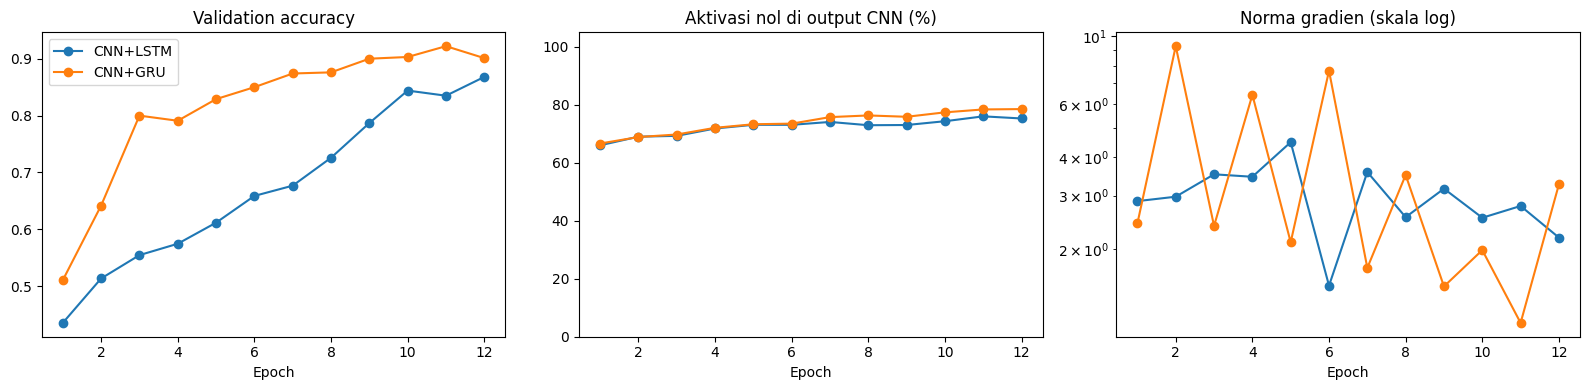

In [9]:
# ============================================================
# SEL 7d: Diagnosis — kenapa CNN+LSTM (mel_1024, Protokol A) kolaps?
# Ukur per epoch: % aktivasi nol di output CNN (dead ReLU) & norma gradien (exploding)
# ============================================================
class Diagnosa(keras.callbacks.Callback):
    def __init__(self, Xb, yb):
        super().__init__()
        self.Xb, self.yb, self.rows = tf.constant(Xb), tf.constant(yb), []

    def on_epoch_end(self, epoch, logs=None):
        # output CNN = input ke RNN (layer Reshape)
        cnn = keras.Model(self.model.input, self.model.get_layer(index=1 + 3 * HP["conv_blocks"]).output)
        a = cnn(self.Xb, training=False).numpy()
        aktivasi_nol = float((a <= 0).mean())                    # porsi nilai nol
        fitur_mati   = float((a.max(axis=(0, 1)) <= 0).mean())   # porsi fitur yg SELALU nol
        with tf.GradientTape() as tape:
            p = self.model(self.Xb, training=False)
            loss = tf.reduce_mean(keras.losses.sparse_categorical_crossentropy(self.yb, p))
        g = tape.gradient(loss, self.model.trainable_variables)
        grad_norm = float(tf.linalg.global_norm([x for x in g if x is not None]))
        self.rows.append(dict(epoch=epoch + 1, loss=logs["loss"], val_acc=logs["val_accuracy"],
                              aktivasi_nol=aktivasi_nol, fitur_mati=fitur_mati, grad_norm=grad_norm))
        print(f"  ep {epoch+1:2d} | loss {logs['loss']:.3f} | val_acc {logs['val_accuracy']:.3f} | "
              f"aktivasi nol {aktivasi_nol:6.1%} | fitur mati {fitur_mati:6.1%} | grad_norm {grad_norm:9.3f}")

d = get_data("mel_1024", "A_segmen")
(Xtr, ytr), (Xva, yva) = d["train"], d["val"]
bidx = np.random.default_rng(0).choice(len(Xtr), 256, replace=False)

DIAG = {}
for mname in ("CNN+LSTM", "CNN+GRU"):          # yang gagal vs yang sehat
    print(f"\n=== {mname} (lr {HP['lr']}, seed {SEED}) ===")
    set_seed(SEED); keras.backend.clear_session()
    rnn, bi = MODELS[mname]
    m = build_model(rnn, bi, input_shape=Xtr.shape[1:])
    cb = Diagnosa(Xtr[bidx], ytr[bidx])
    m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=12,
          batch_size=HP["batch_size"], callbacks=[cb], verbose=0)
    DIAG[mname] = pd.DataFrame(cb.rows)
    DIAG[mname].to_csv(os.path.join(WORK_DIR, f"diagnosa_{mname.replace('+', '')}.csv"), index=False)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for mname, D in DIAG.items():
    ax[0].plot(D.epoch, D.val_acc, marker="o", label=mname)
    ax[1].plot(D.epoch, D.aktivasi_nol * 100, marker="o", label=mname)
    ax[2].plot(D.epoch, D.grad_norm, marker="o", label=mname)
ax[0].set(title="Validation accuracy", xlabel="Epoch")
ax[1].set(title="Aktivasi nol di output CNN (%)", xlabel="Epoch", ylim=(0, 105))
ax[2].set(title="Norma gradien (skala log)", xlabel="Epoch", yscale="log")
ax[0].legend(); plt.tight_layout()
plt.savefig(os.path.join(WORK_DIR, "fig_diagnosa_lstm.png"), dpi=150); plt.show()

In [10]:
# ============================================================
# SEL 7e: Perbaikan — CNN+LSTM mel_1024 Protokol A dengan lr 1e-4 (kandidat Tabel 1 paper)
# ============================================================
HP_FIX = {**HP, "lr": 1e-4}
for s in (42, 43, 44):
    if sudah_jalan("CNN+LSTM", "mel_1024", "A_segmen", seed=s, tag="perbaikan_lr"):
        print(f"seed {s}: SKIP"); continue
    row, h = run_experiment("CNN+LSTM", "mel_1024", "A_segmen", seed=s, tag="perbaikan_lr", hp=HP_FIX)
    cetak(s, 44, row)

L = pd.read_csv(LOG_PATH)
F = L[(L.model == "CNN+LSTM") & (L.fitur == "mel_1024") & (L.protokol == "A_segmen")]
print("\nRingkasan CNN+LSTM mel_1024 Protokol A:")
print(F.groupby("tag").test_acc.agg(["count", "mean", "std", "min", "max"]).round(4).to_string())

catat_deviasi("Learning rate CNN+LSTM",
              "lr 0.001 (nilai 'teroptimasi' dari kandidat {0.1, 0.01, 0.001, 0.0001})",
              "CNN+LSTM mel_1024 memakai lr 0.0001; model lain tetap 0.001",
              "lr 0.001 menyebabkan kolaps (dead ReLU / gradien meledak, lihat fig_diagnosa_lstm); "
              "0.0001 masih dalam ruang pencarian paper")

E0000 00:00:1793574557.305435      24 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/CNN_LSTM_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


[42/44] perbaikan_lr CNN+LSTM     mel_1024  A_segmen  s42 | best_ep 45 | test_acc 0.9429 | f1 0.9430 | track_acc 0.9707 | 26.9 mnt


E0000 00:00:1793576173.441568      24 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/CNN_LSTM_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


[43/44] perbaikan_lr CNN+LSTM     mel_1024  A_segmen  s43 | best_ep 43 | test_acc 0.9329 | f1 0.9328 | track_acc 0.9460 | 26.8 mnt


E0000 00:00:1793577783.720611      24 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/CNN_LSTM_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


[44/44] perbaikan_lr CNN+LSTM     mel_1024  A_segmen  s44 | best_ep 45 | test_acc 0.9349 | f1 0.9351 | track_acc 0.9583 | 26.7 mnt

Ringkasan CNN+LSTM mel_1024 Protokol A:
              count    mean     std     min     max
tag                                                
clipnorm          1  0.9399     NaN  0.9399  0.9399
perbaikan_lr      3  0.9369  0.0053  0.9329  0.9429
replikasi         3  0.2929  0.0568  0.2292  0.3383


## 8. Rekap hasil vs paper + gambar

TABEL 1 — Akurasi test (%) level segmen, Protokol A, seed 42

             Paper mel  Kita mel_1024  Δ mel  Paper MFCC  Kita mfcc_20  Δ MFCC
CNN+LSTM         87.20          33.83 -53.37       76.40         85.29    8.89
CNN+Bi-LSTM      88.00          94.29   6.29       73.69         86.79   13.10
CNN+GRU          87.78          95.70   7.92       71.50         87.19   15.69
CNN+Bi-GRU       89.30          94.19   4.89       76.30         78.68    2.38 

TABEL 1b — Diagnosis CNN+LSTM mel_1024 Protokol A
      tag  seed  best_epoch  test_acc  f1_macro  track_acc
replikasi    42           2    0.3383    0.2564     0.3426
replikasi    43           3    0.3113    0.2487     0.3164
replikasi    44           5    0.2292    0.1390     0.2392
 clipnorm    42          50    0.9399    0.9399     0.9552 

TABEL 2 — Dampak protokol split (mel_1024, akurasi %)

             A per-segmen  B per-lagu  B (level lagu)  Selisih A−B
model                                                             
CNN+L

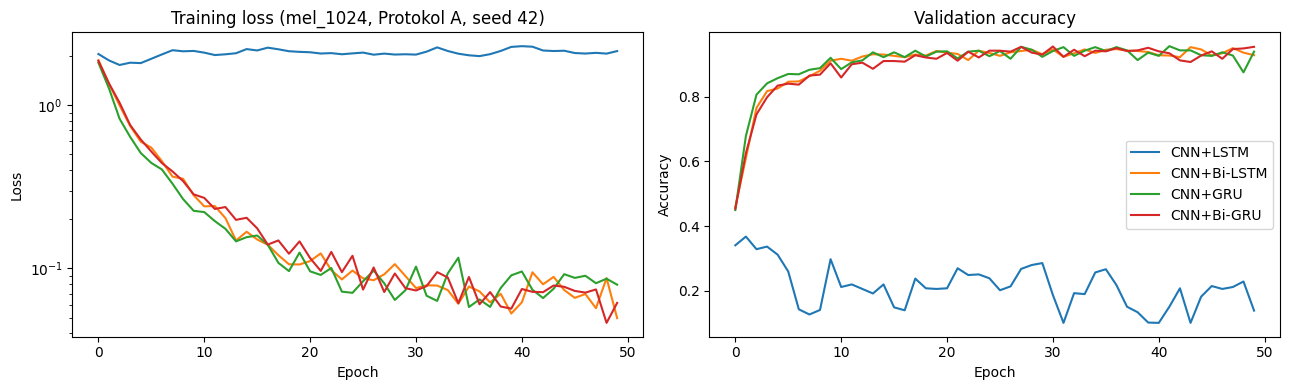

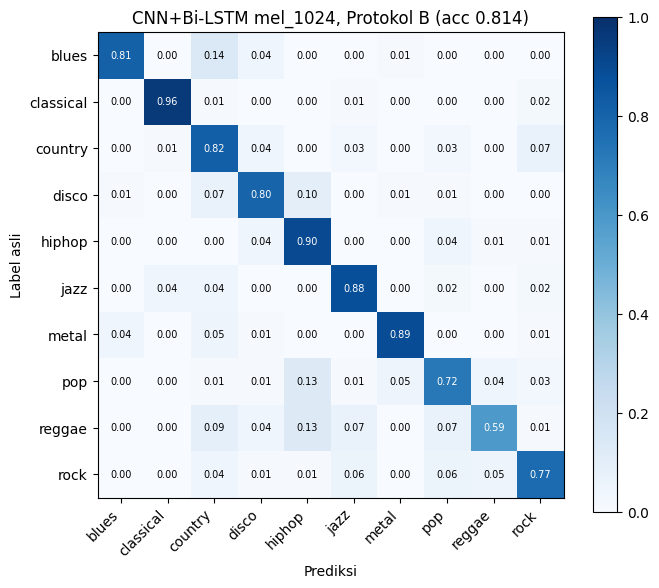

In [11]:
L = pd.read_csv(LOG_PATH)
R = L[L.tag == "replikasi"].copy()
ORDER = list(MODELS)
PAPER = pd.DataFrame({"mel":  [87.20, 88.00, 87.78, 89.30],
                      "mfcc": [76.40, 73.69, 71.50, 76.30]}, index=ORDER)

def ambil(fitur, protokol, seed=SEED, kol="test_acc", data=R):
    s = data[(data.fitur == fitur) & (data.protokol == protokol) & (data.seed == seed)].set_index("model")[kol]
    return (s.reindex(ORDER) * 100).round(2)

# Tabel 1: paper vs replikasi
T1 = pd.DataFrame({"Paper mel": PAPER["mel"], "Kita mel_1024": ambil("mel_1024", "A_segmen"),
                   "Paper MFCC": PAPER["mfcc"], "Kita mfcc_20": ambil("mfcc_20", "A_segmen")})
T1.insert(2, "Δ mel", (T1["Kita mel_1024"] - T1["Paper mel"]).round(2))
T1["Δ MFCC"] = (T1["Kita mfcc_20"] - T1["Paper MFCC"]).round(2)
print("TABEL 1 — Akurasi test (%) level segmen, Protokol A, seed 42\n"); print(T1.to_string(), "\n")

# Tabel 1b: diagnosis CNN+LSTM mel_1024
D = L[(L.model == "CNN+LSTM") & (L.fitur == "mel_1024") & (L.protokol == "A_segmen") &
      (L.tag.isin(["replikasi", "clipnorm"]))]
if len(D) > 1:
    print("TABEL 1b — Diagnosis CNN+LSTM mel_1024 Protokol A")
    print(D[["tag", "seed", "best_epoch", "test_acc", "f1_macro", "track_acc"]].to_string(index=False), "\n")

# Tabel 2: dampak leakage
T2 = pd.DataFrame({"A per-segmen": ambil("mel_1024", "A_segmen"),
                   "B per-lagu": ambil("mel_1024", "B_lagu"),
                   "B (level lagu)": ambil("mel_1024", "B_lagu", kol="track_acc")})
T2["Selisih A−B"] = (T2["A per-segmen"] - T2["B per-lagu"]).round(2)
print("TABEL 2 — Dampak protokol split (mel_1024, akurasi %)\n"); print(T2.to_string(), "\n")

# Tabel 3: dampak n_fft
T3 = pd.DataFrame({"n_fft 1024": ambil("mel_1024", "A_segmen"), "n_fft 2048": ambil("mel_2048", "A_segmen")})
T3["Selisih"] = (T3["n_fft 2048"] - T3["n_fft 1024"]).round(2)
print("TABEL 3 — Dampak panjang window STFT (Protokol A, akurasi %)\n"); print(T3.to_string(), "\n")

for name, T in [("tabel1_paper_vs_replikasi", T1), ("tabel2_leakage", T2), ("tabel3_nfft", T3)]:
    T.to_csv(os.path.join(WORK_DIR, f"{name}.csv"))
if len(D) > 1:
    D.to_csv(os.path.join(WORK_DIR, "tabel1b_diagnosis_lstm.csv"), index=False)

# Gambar: kurva training
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for m in ORDER:
    hh = pd.read_csv(os.path.join(HIST_DIR, run_key("replikasi", m, "mel_1024", "A_segmen", SEED) + ".csv"))
    ax[0].plot(hh["loss"], label=m); ax[1].plot(hh["val_accuracy"], label=m)
ax[0].set(title="Training loss (mel_1024, Protokol A, seed 42)", xlabel="Epoch", ylabel="Loss", yscale="log")
ax[1].set(title="Validation accuracy", xlabel="Epoch", ylabel="Accuracy"); ax[1].legend()
plt.tight_layout(); plt.savefig(os.path.join(WORK_DIR, "fig_kurva_training.png"), dpi=150); plt.show()

# Gambar: confusion matrix model terbaik Protokol B
B = R[(R.protokol == "B_lagu") & (R.seed == SEED)].sort_values("test_acc", ascending=False).iloc[0]
yt, yp = np.load(os.path.join(PRED_DIR, run_key("replikasi", B.model, B.fitur, B.protokol, SEED) + ".npy"))
cm = confusion_matrix(yt, yp, normalize="true")
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(GENRES))); ax.set_xticklabels(GENRES, rotation=45, ha="right")
ax.set_yticks(range(len(GENRES))); ax.set_yticklabels(GENRES)
for i in range(len(GENRES)):
    for j in range(len(GENRES)):
        ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if cm[i, j] > 0.5 else "black")
ax.set(xlabel="Prediksi", ylabel="Label asli", title=f"{B.model} {B.fitur}, Protokol B (acc {B.test_acc:.3f})")
fig.colorbar(im); plt.tight_layout()
plt.savefig(os.path.join(WORK_DIR, "fig_confusion_B.png"), dpi=150); plt.show()

             Paper mel  Kita mel  Paper MFCC  Kita MFCC  Δ mel  Δ MFCC
CNN+LSTM         87.20     93.69       76.40      85.29   6.49    8.89
CNN+Bi-LSTM      88.00     94.29       73.69      86.79   6.29   13.10
CNN+GRU          87.78     95.70       71.50      87.19   7.92   15.69
CNN+Bi-GRU       89.30     94.19       76.30      78.68   4.89    2.38

† CNN+LSTM mel: lr 0.0001, rata-rata 3 seed = 93.69 ± 0.53; lr 0.001 kolaps pada 3 dari 3 run


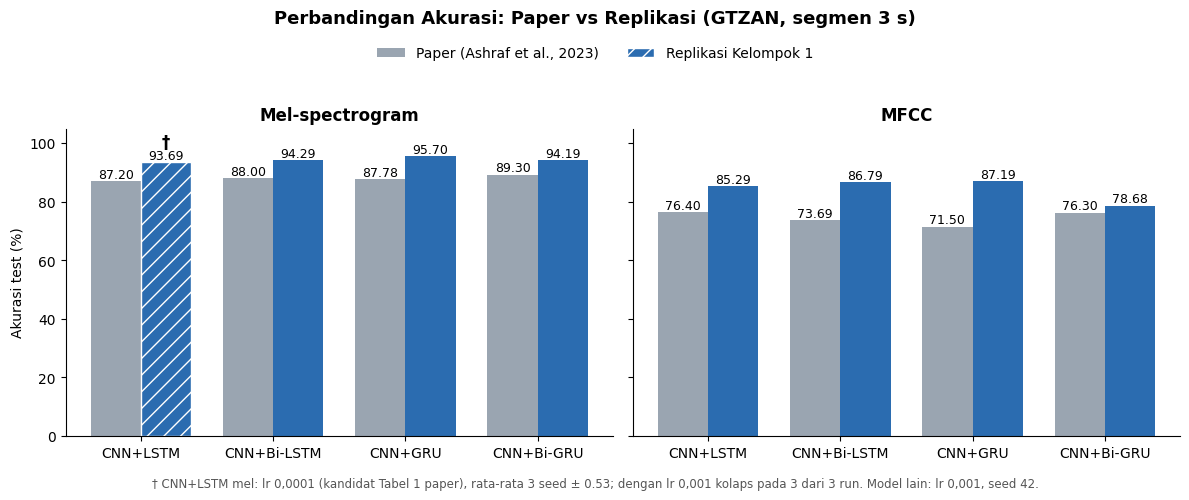

In [12]:
# ============================================================
# SEL 8b: Grafik & tabel paper vs replikasi (CNN+LSTM mel memakai hasil perbaikan lr 1e-4)
# ============================================================
L = pd.read_csv(LOG_PATH)
ORDER = list(MODELS)

def acc(model, fitur, tag="replikasi", seed=SEED):
    r = L[(L.tag == tag) & (L.model == model) & (L.fitur == fitur) & (L.protokol == "A_segmen")]
    if seed is not None:
        r = r[r.seed == seed]
    return r.test_acc.mean() * 100, (r.test_acc.std() * 100 if len(r) > 1 else np.nan)

paper_mel  = [87.20, 88.00, 87.78, 89.30]
paper_mfcc = [76.40, 73.69, 71.50, 76.30]
kita_mel   = [acc(m, "mel_1024")[0] for m in ORDER]
kita_mfcc  = [acc(m, "mfcc_20")[0] for m in ORDER]
lstm_fix, lstm_sd = acc("CNN+LSTM", "mel_1024", tag="perbaikan_lr", seed=None)
kita_mel[0] = lstm_fix                                   # ganti dengan hasil perbaikan

lr3 = L[(L.tag == "replikasi") & (L.model == "CNN+LSTM") & (L.fitur == "mel_1024") & (L.protokol == "A_segmen")]
n_kolaps, n_run = int((lr3.test_acc < 0.5).sum()), len(lr3)

T = pd.DataFrame({"Paper mel": paper_mel, "Kita mel": np.round(kita_mel, 2),
                  "Paper MFCC": paper_mfcc, "Kita MFCC": np.round(kita_mfcc, 2)}, index=ORDER)
T["Δ mel"]  = (T["Kita mel"] - T["Paper mel"]).round(2)
T["Δ MFCC"] = (T["Kita MFCC"] - T["Paper MFCC"]).round(2)
print(T.to_string())
print(f"\n† CNN+LSTM mel: lr 0.0001, rata-rata 3 seed = {lstm_fix:.2f} ± {lstm_sd:.2f}; "
      f"lr 0.001 kolaps pada {n_kolaps} dari {n_run} run")
T.to_csv(os.path.join(WORK_DIR, "tabel1_final_paper_vs_replikasi.csv"))

fig, axs = plt.subplots(1, 2, figsize=(12, 4.9), sharey=True)
x, w = np.arange(4), 0.38
for ax, (judul, p, k) in zip(axs, [("Mel-spectrogram", paper_mel, kita_mel), ("MFCC", paper_mfcc, kita_mfcc)]):
    b1 = ax.bar(x - w/2, p, w, label="Paper (Ashraf et al., 2023)", color="#9aa5b1")
    b2 = ax.bar(x + w/2, k, w, label="Replikasi Kelompok 1", color="#2b6cb0")
    for b in list(b1) + list(b2):
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 1, f"{b.get_height():.2f}", ha="center", fontsize=9)
    ax.set_xticks(x); ax.set_xticklabels(ORDER); ax.set_title(judul, fontsize=12, weight="bold")
    ax.set_ylim(0, 105); ax.spines[["top", "right"]].set_visible(False)
axs[0].patches[4].set_hatch("//"); axs[0].patches[4].set_edgecolor("white")   # tandai bar CNN+LSTM yang diperbaiki
axs[0].text(x[0] + w/2, kita_mel[0] + 5, "†", ha="center", fontsize=12, weight="bold")
axs[0].set_ylabel("Akurasi test (%)")
h, l = axs[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper center", bbox_to_anchor=(0.5, 0.93), ncol=2, frameon=False, fontsize=10)
fig.suptitle("Perbandingan Akurasi: Paper vs Replikasi (GTZAN, segmen 3 s)", fontsize=13, weight="bold")
fig.text(0.5, 0.005, f"† CNN+LSTM mel: lr 0,0001 (kandidat Tabel 1 paper), rata-rata 3 seed ± {lstm_sd:.2f}; "
         f"dengan lr 0,001 kolaps pada {n_kolaps} dari {n_run} run. Model lain: lr 0,001, seed 42.",
         ha="center", fontsize=8.5, color="#555")
plt.tight_layout(rect=[0, 0.03, 1, 0.88])
plt.savefig(os.path.join(WORK_DIR, "fig_perbandingan_final.png"), dpi=200); plt.show()

## 9. Simpan paket hasil (requirements, catatan deviasi, zip)

In [13]:
with open(os.path.join(WORK_DIR, "requirements.txt"), "w") as f:
    f.write(f"# Python {versions['python']} | Kaggle GPU T4\n")
    for k in ("numpy", "pandas", "librosa", "soundfile", "tensorflow", "scikit-learn", "matplotlib"):
        f.write(f"{k}=={versions[k]}\n")

with open(os.path.join(WORK_DIR, "catatan_deviasi.md"), "w") as f:
    f.write("| No | Aspek | Paper | Replikasi kita | Alasan |\n|---|---|---|---|---|\n")
    for i, d in enumerate(DEVIASI.values(), 1):
        f.write(f"| {i} | {d['aspek']} | {d['paper']} | {d['kita']} | {d['alasan']} |\n")

files = ["log_eksperimen.csv", "log_deviasi.json", "catatan_deviasi.md", "requirements.txt",
         "segments.csv", "splits.json", "history", "pred"] + \
        sorted(f for f in os.listdir(WORK_DIR) if f.startswith(("tabel", "fig_")))
subprocess.run(["zip", "-qr", "hasil_minggu1.zip", *files], cwd=WORK_DIR, check=True)
print("hasil_minggu1.zip:", round(os.path.getsize(os.path.join(WORK_DIR, "hasil_minggu1.zip")) / 1e6, 1), "MB")
print(open(os.path.join(WORK_DIR, "catatan_deviasi.md")).read())

hasil_minggu1.zip: 0.8 MB
| No | Aspek | Paper | Replikasi kita | Alasan |
|---|---|---|---|---|
| 1 | Dataset | GTZAN 1000 klip, format mp3 | Versi Kaggle (andradaolteanu), .wav; 999 klip valid (file rusak dibuang) | Paper tidak menyebut sumber unduhan; jazz.00054 tidak bisa dibaca |
| 2 | Segmentasi | 30 s -> 3 s, penanganan sisa tidak disebut | 10 segmen non-overlap; 9 klip < 30 s di-zero-pad, kelebihan dipotong | Agar tiap lagu tepat 10 segmen |
| 3 | Split | 8:1:1, level tidak disebut | Protokol A per-segmen (dugaan paper) & B per-lagu, stratified, seed 42 | Ambiguitas paper; B untuk mengukur dampak leakage |
| 4 | Parameter STFT | Sec 3.2: n_fft 1024/hop 512, shape (128,129); Sec 4: window 2048/hop 512, shape (640,128) | Dua konfigurasi diuji: mel_1024 & mel_2048, Hann, center=True -> (128,130) | Paper tidak konsisten; shape (640,128) tidak bisa diturunkan dari segmen 3 s |
| 5 | MFCC | 13–20 koefisien, parameter framing tidak disebut | 20 koefisien dari log-mel 128 band, n_fft 2

## 10. Ringkasan temuan otomatis dari log
from IPython.display import Markdown, display

L = pd.read_csv(LOG_PATH)
ORDER = list(MODELS)
R = L[(L.tag == "replikasi") & (L.seed == SEED)]

def kol(fitur, protokol, k="test_acc"):
    s = R[(R.fitur == fitur) & (R.protokol == protokol)].set_index("model")[k]
    return (s.reindex(ORDER) * 100).round(2)

q = lambda tag: L[(L.tag == tag) & (L.model == "CNN+LSTM") & (L.fitur == "mel_1024") &
                  (L.protokol == "A_segmen")].test_acc * 100
lstm_lr3, lstm_fix, lstm_clip = q("replikasi"), q("perbaikan_lr"), q("clipnorm")

#### Tabel ringkasan 
S = pd.DataFrame({
    "Paper mel":          [87.20, 88.00, 87.78, 89.30],
    "A mel_1024 (final)": kol("mel_1024", "A_segmen"),
    "A mel_2048":         kol("mel_2048", "A_segmen"),
    "B mel_1024":         kol("mel_1024", "B_lagu"),
    "Paper MFCC":         [76.40, 73.69, 71.50, 76.30],
    "A mfcc_20":          kol("mfcc_20", "A_segmen"),
}, index=ORDER)
S.loc["CNN+LSTM", "A mel_1024 (final)"] = round(lstm_fix.mean(), 2)
display(S)
S.to_csv(os.path.join(WORK_DIR, "tabel_ringkasan_final.csv"))

#### Angka untuk poin temuan 
melA   = S["A mel_1024 (final)"]
best_A = melA.idxmax()
lain   = [m for m in ORDER if m != "CNN+LSTM"]                 # varian dengan lr yang sama (0,001)
gap_mel_mfcc = (melA - S["A mfcc_20"]).mean()
leak  = (S.loc[lain, "A mel_1024 (final)"] - S.loc[lain, "B mel_1024"])
nfft  = (S.loc[lain, "A mel_2048"] - S.loc[lain, "A mel_1024 (final)"])
best_B = S["B mel_1024"].idxmax()
n_kolaps = int((lstm_lr3 < 50).sum())

#### Kelas sulit & kebingungan terbesar dari model terbaik Protokol B
teks_kelas = "-"
try:
    yt, yp = np.load(os.path.join(PRED_DIR, run_key("replikasi", best_B, "mel_1024", "B_lagu", SEED) + ".npy"))
    cm = confusion_matrix(yt, yp, normalize="true")
    recall = pd.Series(np.diag(cm), index=GENRES).sort_values()
    off = cm.copy(); np.fill_diagonal(off, 0)
    top = np.dstack(np.unravel_index(np.argsort(off, axis=None)[::-1][:3], off.shape))[0]
    teks_kelas = (", ".join(f"{g} ({v:.2f})" for g, v in recall.head(4).items()) + "; kebingungan terbesar: " +
                  ", ".join(f"{GENRES[i]}→{GENRES[j]} ({off[i, j]:.2f})" for i, j in top))
except FileNotFoundError:
    pass

clip_txt = ", ".join(f"{v:.2f}%" for v in lstm_clip) if len(lstm_clip) else "-"

display(Markdown(f"""
**Temuan utama (run {L.waktu.iloc[-1][:10]}, GPU T4)**

1. **Mel-spectrogram > MFCC**, rata-rata unggul **{gap_mel_mfcc:.2f} poin**; model terbaik Protokol A adalah
   **{best_A} ({melA[best_A]:.2f}%)** vs paper CNN+Bi-GRU 89,30%. Selisih antar-arsitektur hanya
   {melA.max() - melA.min():.2f} poin → perlu multi-seed & uji statistik sebelum disebut signifikan.
2. **Leakage:** split per-segmen (A) menaikkan akurasi **{leak.min():.1f}–{leak.max():.1f} poin** dibanding split per-lagu (B).
   Pada Protokol B model terbaik adalah **{best_B} ({S.loc[best_B, 'B mel_1024']:.2f}%)** → klaim "Bi-GRU terbaik" tidak robust.
3. **n_fft 1024 vs 2048:** selisih **{nfft.min():+.2f} s.d. {nfft.max():+.2f} poin** → inkonsistensi parameter STFT di paper
   tidak kritis; perbedaan resolusi frekuensi (21,5 vs 10,8 Hz) diredam oleh mel filter bank 128 band.
4. **Anomali CNN+LSTM (mel_1024) & perbaikannya:** dengan lr 0,001 training **kolaps pada {n_kolaps} dari {len(lstm_lr3)} run**
   (rata-rata {lstm_lr3.mean():.2f}%), loss terkunci di ≈ ln(10). Diagnosis (Sel 7d) menunjukkan aktivasi & gradien normal
   sebelum kolaps → kolaps terjadi mendadak akibat langkah update terlalu besar. Dengan **lr 0,0001** (masih kandidat Tabel 1
   paper) hasilnya **{lstm_fix.mean():.2f} ± {lstm_fix.std():.2f}% pada {len(lstm_fix)} seed**, konsisten dengan varian lain.
   Gradient clipping (clipnorm 1,0) tidak konsisten: {clip_txt}.
5. **Kelas tersulit (Protokol B, {best_B}):** {teks_kelas}.
6. **Reprodusibilitas:** operasi cuDNN di GPU tidak sepenuhnya deterministik, sehingga seed yang sama dapat memberi hasil
   berbeda antar-run (contoh: CNN+Bi-LSTM 94,29% pada run 26 Okt vs {melA['CNN+Bi-LSTM']:.2f}% pada run ini).
"""))